# Benchmark Structure Prediction Methods

In [1]:
import collections
import itertools

import IPython.display as ipy_display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pingouin as pg
import seaborn as sns
from matplotlib.axes import Axes
from matplotlib.ticker import PercentFormatter
from scipy import stats
from sklearn.metrics import auc, precision_recall_curve, roc_auc_score

In [2]:
sequences = pd.read_csv('../data/interim/sequences_sample_1500.csv', index_col='index')
sequences['fold'] = sequences['fold'].astype(str)

## Antigen Specificity

In [3]:
def calculate_performance(pae_scores: pd.Series, labels: pd.Series) -> pd.Series:
    roc_auc = 1 - roc_auc_score(labels, pae_scores)
    roc_auc01 = 1 - roc_auc_score(labels, pae_scores, max_fpr=0.1)

    precision, recall, _ = precision_recall_curve(labels, pae_scores)
    pr_auc = 1 - auc(recall, precision)

    return pd.Series({'roc_auc': roc_auc, 'roc_auc_01': roc_auc01, 'pr_auc': pr_auc})


def format_metric_name(metric_name: str) -> str:
    return metric_name.upper().replace('_01', ' 0.1').replace('_', '-')

In [4]:
af3_confidence_scores = pd.read_csv('../data/interim/confidence_scores_af3_af3_tcrmodel2_3_recycles_1500.csv')
af3_confidence_scores['model'] = 'AlphaFold 3'

In [5]:
af3_confidence_scores['top_rank'] = False
af3_confidence_scores.loc[af3_confidence_scores.groupby('name')['ranking_score'].idxmax(), 'top_rank'] = True

In [6]:
boltz_confidence_scores = pd.read_csv('../data/interim/confidence_scores_boltz_af3_tcrmodel2_1500.csv')
boltz_confidence_scores['model'] = 'Boltz-2'

In [7]:
boltz_confidence_scores['top_rank'] = False
boltz_confidence_scores.loc[boltz_confidence_scores.groupby('name')['confidence_score'].idxmax(), 'top_rank'] = True

In [8]:
chai_confidence_scores = pd.read_csv('../data/interim/confidence_scores_chai_af3_tcrmodel2_1500.csv')
chai_confidence_scores['model'] = 'Chai-1'

In [9]:
chai_confidence_scores['top_rank'] = False
chai_confidence_scores.loc[chai_confidence_scores.groupby('name')['aggregate_score'].idxmax(), 'top_rank'] = True

In [10]:
af2_confidence_scores = pd.read_csv('../data/interim/confidence_scores_af2_af3_tcrmodel2_1500.csv')
af2_confidence_scores['model'] = 'AlphaFold 2'

In [11]:
af2_confidence_scores['top_rank'] = False
af2_confidence_scores.loc[af2_confidence_scores.groupby('name')['ranking_confidence'].idxmax(), 'top_rank'] = True

In [12]:
confidence_scores = pd.concat(
    [af3_confidence_scores, boltz_confidence_scores, chai_confidence_scores, af2_confidence_scores]
).reset_index(drop=True)

In [13]:
confidence_scores = confidence_scores.merge(sequences, how='left', left_on='name', right_index=True)

### Overall

In [14]:
metric_scores = confidence_scores.groupby('model').apply(
    lambda group: calculate_performance(group['cdr_pmhc_pae_score'], group['label']), include_groups=False
)

metric_scores_top_rank = (
    confidence_scores.query('top_rank')
    .groupby('model')
    .apply(lambda group: calculate_performance(group['cdr_pmhc_pae_score'], group['label']), include_groups=False)
)

print('All')
ipy_display.display(metric_scores)

print()

print('Top Ranked')
ipy_display.display(metric_scores_top_rank)

All


,roc_auc,roc_auc_01,pr_auc
model,,,
AlphaFold 2,0.550476,0.507572,0.535067
AlphaFold 3,0.601772,0.504012,0.553651
Boltz-2,0.562251,0.513222,0.549348
Chai-1,0.612472,0.509811,0.568085



Top Ranked


,roc_auc,roc_auc_01,pr_auc
model,,,
AlphaFold 2,0.541764,0.499949,0.516920
AlphaFold 3,0.601243,0.501511,0.550686
Boltz-2,0.549703,0.517361,0.547792
Chai-1,0.610727,0.510232,0.566772


### Bootstrap

In [15]:
NUM_SAMPLES = 25
SAMPLE_SIZE = 500

names = confidence_scores['name'].unique()
rng = np.random.default_rng(123)

samples_metric_scores = []
samples_metric_scores_top_rank = []
for sample_num in range(1, NUM_SAMPLES + 1):
    sample_names = rng.choice(names, SAMPLE_SIZE)

    sample = confidence_scores[confidence_scores['name'].isin(sample_names)]

    sample_metric_scores = (
        sample.groupby('model')
        .apply(lambda group: calculate_performance(group['cdr_pmhc_pae_score'], group['label']), include_groups=False)
        .reset_index()
    )
    sample_metric_scores['sample_num'] = sample_num

    samples_metric_scores.append(sample_metric_scores)

    sample_metric_scores_top_rank = (
        sample.query('top_rank')
        .groupby('model')
        .apply(lambda group: calculate_performance(group['cdr_pmhc_pae_score'], group['label']), include_groups=False)
        .reset_index()
    )

    sample_metric_scores_top_rank['sample_num'] = sample_num

    samples_metric_scores_top_rank.append(sample_metric_scores_top_rank)

samples_metric_scores = pd.concat(samples_metric_scores).reset_index(drop=True)
samples_metric_scores_top_rank = pd.concat(samples_metric_scores_top_rank).reset_index(drop=True)

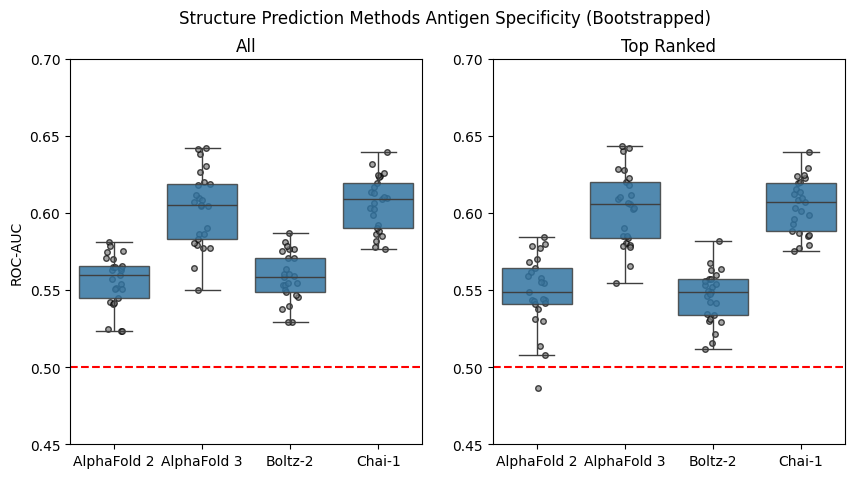

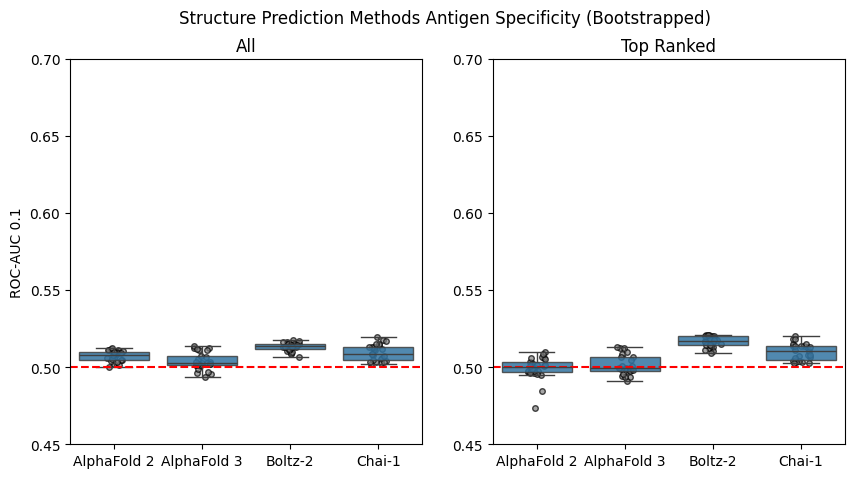

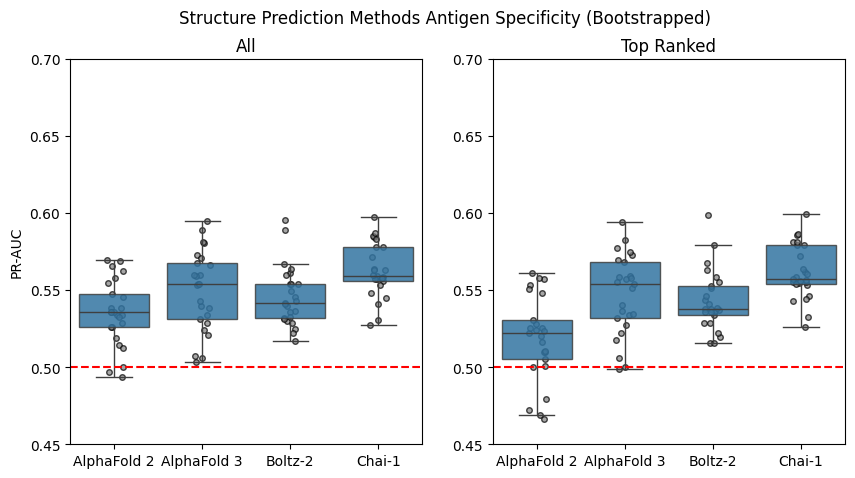

In [16]:
for metric_name in ('roc_auc', 'roc_auc_01', 'pr_auc'):
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    fig.suptitle('Structure Prediction Methods Antigen Specificity (Bootstrapped)')

    for i, (ax, title, data) in enumerate(
        zip(axes, ('All', 'Top Ranked'), (samples_metric_scores, samples_metric_scores_top_rank), strict=True)
    ):
        sns.stripplot(
            data,
            x='model',
            y=metric_name,
            color='grey',
            zorder=1,
            marker='o',
            size=4,
            edgecolor='black',
            linewidth=1,
            alpha=0.70,
            ax=ax,
        )
        sns.boxplot(data, x='model', y=metric_name, boxprops={'alpha': 0.85}, showfliers=False, ax=ax)

        ax.axhline(0.5, color='r', linestyle='dashed')

        ax.set_title(title)
        ax.set_xlabel('')
        ax.set_ylim(0.45, 0.7)

        if i == 0:
            ax.set_ylabel(format_metric_name(metric_name))

        else:
            ax.set_ylabel('')

    plt.show()

In [17]:
print('All')
scores_agg = metric_scores.join(
    samples_metric_scores.set_index('sample_num').groupby('model').agg('sem'), rsuffix='_sem'
)
for metric in 'roc_auc', 'roc_auc_01', 'pr_auc':
    scores_agg[f'{metric}_ci'] = scores_agg.apply(
        lambda row, metric=metric: (row[metric] - row[f'{metric}_sem'], row[metric] + row[f'{metric}_sem']), axis=1
    )

ipy_display.display(scores_agg)

print()

print('Top Ranked')
scores_agg_top_rank = metric_scores_top_rank.join(
    samples_metric_scores_top_rank.set_index('sample_num').groupby('model').agg('sem'), rsuffix='_sem'
)
for metric in 'roc_auc', 'roc_auc_01', 'pr_auc':
    scores_agg_top_rank[f'{metric}_ci'] = scores_agg_top_rank.apply(
        lambda row, metric=metric: (row[metric] - row[f'{metric}_sem'], row[metric] + row[f'{metric}_sem']), axis=1
    )

ipy_display.display(scores_agg_top_rank)

All


,roc_auc,roc_auc_01,pr_auc,roc_auc_sem,roc_auc_01_sem,pr_auc_sem,roc_auc_ci,roc_auc_01_ci,pr_auc_ci
model,,,,,,,,,
AlphaFold 2,0.550476,0.507572,0.535067,0.003331,0.000701,0.004288,"(0.5471446037625589, 0.5538074317929966)","(0.5068712195492632, 0.5082728272343625)","(0.5307790803562629, 0.5393556856332298)"
AlphaFold 3,0.601772,0.504012,0.553651,0.004898,0.001143,0.005186,"(0.5968738266082179, 0.6066703511695599)","(0.5028691543255845, 0.5051555474288014)","(0.5484650038412551, 0.5588367179419707)"
Boltz-2,0.562251,0.513222,0.549348,0.003169,0.000544,0.003857,"(0.55908154502507, 0.5654200727527078)","(0.5126780052736929, 0.5137667198725059)","(0.5454910431405611, 0.5532049072197429)"
Chai-1,0.612472,0.509811,0.568085,0.003559,0.001039,0.003490,"(0.6089123158641335, 0.6160309019136442)","(0.5087714434840848, 0.5108503576855058)","(0.5645952467937889, 0.5715756789120532)"



Top Ranked


,roc_auc,roc_auc_01,pr_auc,roc_auc_sem,roc_auc_01_sem,pr_auc_sem,roc_auc_ci,roc_auc_01_ci,pr_auc_ci
model,,,,,,,,,
AlphaFold 2,0.541764,0.499949,0.516920,0.004709,0.001515,0.005539,"(0.5370548468195165, 0.5464722642915946)","(0.4984337508546732, 0.5014633251687187)","(0.5113810269127083, 0.5224595930183306)"
AlphaFold 3,0.601243,0.501511,0.550686,0.004857,0.001280,0.005212,"(0.5963853672024491, 0.6060999661308843)","(0.5002309347479913, 0.502791287474231)","(0.5454735318621452, 0.5558980312507839)"
Boltz-2,0.549703,0.517361,0.547792,0.003386,0.000693,0.003925,"(0.5463174023224903, 0.5530888198997318)","(0.5166684277264283, 0.5180543792911155)","(0.5438673370593794, 0.5517175421039116)"
Chai-1,0.610727,0.510232,0.566772,0.003530,0.001086,0.003525,"(0.6071968642832185, 0.6142573579390037)","(0.5091452789919946, 0.5113178789027422)","(0.5632470028029067, 0.5702967610606392)"


In [18]:
def calculate_differences(sample_groups: pd.DataFrame) -> pd.DataFrame:
    groups = list(sample_groups.groupby('model'))

    differences = {
        'group_name_i': [],
        'group_name_j': [],
        'difference_roc_auc': [],
        'difference_roc_auc_01': [],
        'difference_pr_auc': [],
    }

    for i, (group_name_i, group_i) in enumerate(groups):
        for group_name_j, group_j in groups[i + 1 :]:
            for metric in 'roc_auc', 'roc_auc_01', 'pr_auc':
                difference = group_i[metric].iloc[0] - group_j[metric].iloc[0]
                differences[f'difference_{metric}'].append(difference)

            differences['group_name_i'].append(group_name_i)
            differences['group_name_j'].append(group_name_j)

    return pd.DataFrame(differences)

In [19]:
print('All')

metric_scores_differences = calculate_differences(metric_scores)
samples_metric_scores_differences = (
    samples_metric_scores.groupby('sample_num')
    .apply(calculate_differences, include_groups=False)
    .groupby(['group_name_i', 'group_name_j'])
    .agg(['sem'])
)
samples_metric_scores_differences.columns = ['_'.join(column) for column in samples_metric_scores_differences.columns]
samples_metric_scores_differences = samples_metric_scores_differences.reset_index()

metric_scores_differences = metric_scores_differences.merge(samples_metric_scores_differences)

for metric in 'roc_auc', 'roc_auc_01', 'pr_auc':
    metric_scores_differences[f'{metric}_ci'] = metric_scores_differences.apply(
        lambda row, metric=metric: (
            row[f'difference_{metric}'] - row[f'difference_{metric}_sem'],
            row[f'difference_{metric}'] + row[f'difference_{metric}_sem'],
        ),
        axis=1,
    )

ipy_display.display(metric_scores_differences)

print()

print('Top Rank')

metric_scores_differences_top_rank = calculate_differences(metric_scores_top_rank)
samples_metric_scores_differences_top_rank = (
    samples_metric_scores_top_rank.groupby('sample_num')
    .apply(calculate_differences, include_groups=False)
    .groupby(['group_name_i', 'group_name_j'])
    .agg(['sem'])
)
samples_metric_scores_differences_top_rank.columns = [
    '_'.join(column) for column in samples_metric_scores_differences_top_rank.columns
]
samples_metric_scores_differences_top_rank = samples_metric_scores_differences_top_rank.reset_index()

metric_scores_differences_top_rank = metric_scores_differences_top_rank.merge(
    samples_metric_scores_differences_top_rank
)

for metric in 'roc_auc', 'roc_auc_01', 'pr_auc':
    metric_scores_differences_top_rank[f'{metric}_ci'] = metric_scores_differences_top_rank.apply(
        lambda row, metric=metric: (
            row[f'difference_{metric}'] - row[f'difference_{metric}_sem'],
            row[f'difference_{metric}'] + row[f'difference_{metric}_sem'],
        ),
        axis=1,
    )

ipy_display.display(metric_scores_differences_top_rank)

print()

All


,group_name_i,group_name_j,difference_roc_auc,difference_roc_auc_01,difference_pr_auc,difference_roc_auc_sem,difference_roc_auc_01_sem,difference_pr_auc_sem,roc_auc_ci,roc_auc_01_ci,pr_auc_ci
0,AlphaFold 2,AlphaFold 3,-0.051296,0.003560,-0.018583,0.002771,0.000989,0.002437,"(-0.05406706614897864, -0.0485250760732436)","(0.002570794039817595, 0.004548550989422126)","(-0.02102019304539518, -0.0161467627483379)"
1,AlphaFold 2,Boltz-2,-0.011775,-0.005650,-0.014281,0.004193,0.000993,0.002991,"(-0.01596825977938343, -0.007581322442838823)","(-0.006643620219354735, -0.004657058143218356)","(-0.017271976468030862, -0.011289207902780481)"
2,AlphaFold 2,Chai-1,-0.061996,-0.002239,-0.033018,0.003668,0.001026,0.002473,"(-0.06566365745178493, -0.05832752477043723)","(-0.0032645008063006973, -0.0012132535796641742)","(-0.03549065456435681, -0.03054550515199265)"
3,AlphaFold 3,Boltz-2,0.039521,-0.009210,0.004303,0.004940,0.001281,0.003696,"(0.0345808563326, 0.04446170366739998)","(-0.010491319610850348, -0.007928703780962464)","(0.0006065825216541474, 0.00799918890126759)"
4,AlphaFold 3,Chai-1,-0.010700,-0.005799,-0.014435,0.003173,0.001180,0.002847,"(-0.013872121878446, -0.007526918121553925)","(-0.006978121867136504, -0.004618977548068088)","(-0.017281114470388742, -0.01158808945222764)"
5,Boltz-2,Chai-1,-0.050221,0.003411,-0.018737,0.003583,0.001167,0.002753,"(-0.053804051162890394, -0.046637548837109515)","(0.002244056126197289, 0.00457886785041093)","(-0.021490395840010473, -0.015984579505527646)"



Top Rank


,group_name_i,group_name_j,difference_roc_auc,difference_roc_auc_01,difference_pr_auc,difference_roc_auc_sem,difference_roc_auc_01_sem,difference_pr_auc_sem,roc_auc_ci,roc_auc_01_ci,pr_auc_ci
0,AlphaFold 2,AlphaFold 3,-0.059479,-0.001563,-0.033765,0.003440,0.001242,0.003233,"(-0.06291883053528291, -0.05603939168693939)","(-0.0028049025225802314, -0.000320243676250188)","(-0.03699833661923487, -0.030532606562655364)"
1,AlphaFold 2,Boltz-2,-0.007940,-0.017413,-0.030872,0.005010,0.001584,0.004478,"(-0.012950012490592888, -0.0029290986205180673)","(-0.018997161040238925, -0.015828569953913057)","(-0.03535005716227235, -0.026394202069979777)"
2,AlphaFold 2,Chai-1,-0.068964,-0.010283,-0.049852,0.004918,0.001409,0.004003,"(-0.07388150050688508, -0.06404561060422603)","(-0.011692355375970494, -0.008873726495374405)","(-0.05385488351124201, -0.04584826042126511)"
3,AlphaFold 3,Boltz-2,0.051540,-0.015850,0.002893,0.005261,0.001435,0.004226,"(0.04627806257034872, 0.05680104854076262)","(-0.01728551383263142, -0.014415070962690141)","(-0.001332930682614657, 0.007119614632252762)"
4,AlphaFold 3,Chai-1,-0.009484,-0.008720,-0.016086,0.003201,0.001353,0.003132,"(-0.012685109010012042, -0.0062837798788767715)","(-0.01007371521033482, -0.00736722046217966)","(-0.01921833038222128, -0.012953870368395605)"
5,Boltz-2,Chai-1,-0.061024,0.007130,-0.018979,0.004043,0.001329,0.003324,"(-0.06506698494442018, -0.056981015055579974)","(0.0058011951989925935, 0.00845845392381449)","(-0.022303230167665732, -0.01565565453258926)"


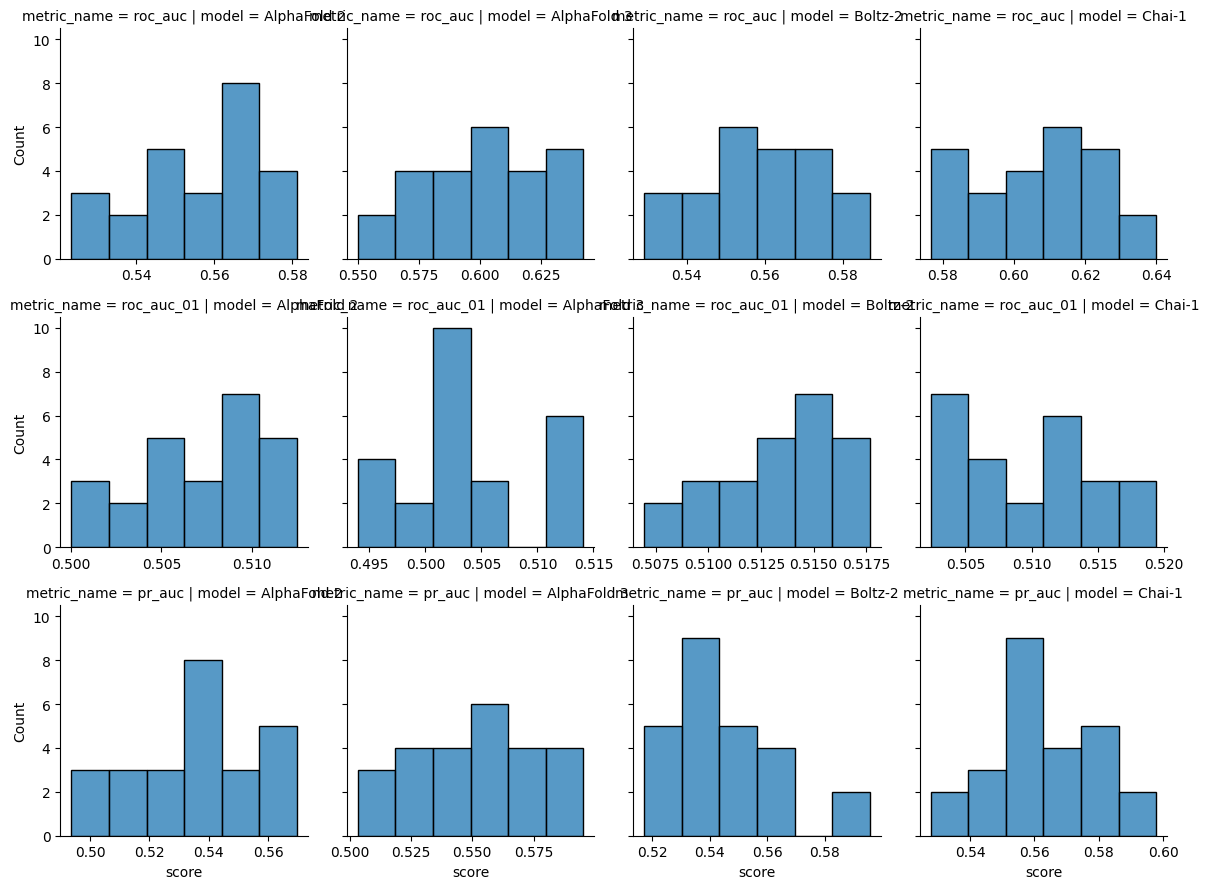

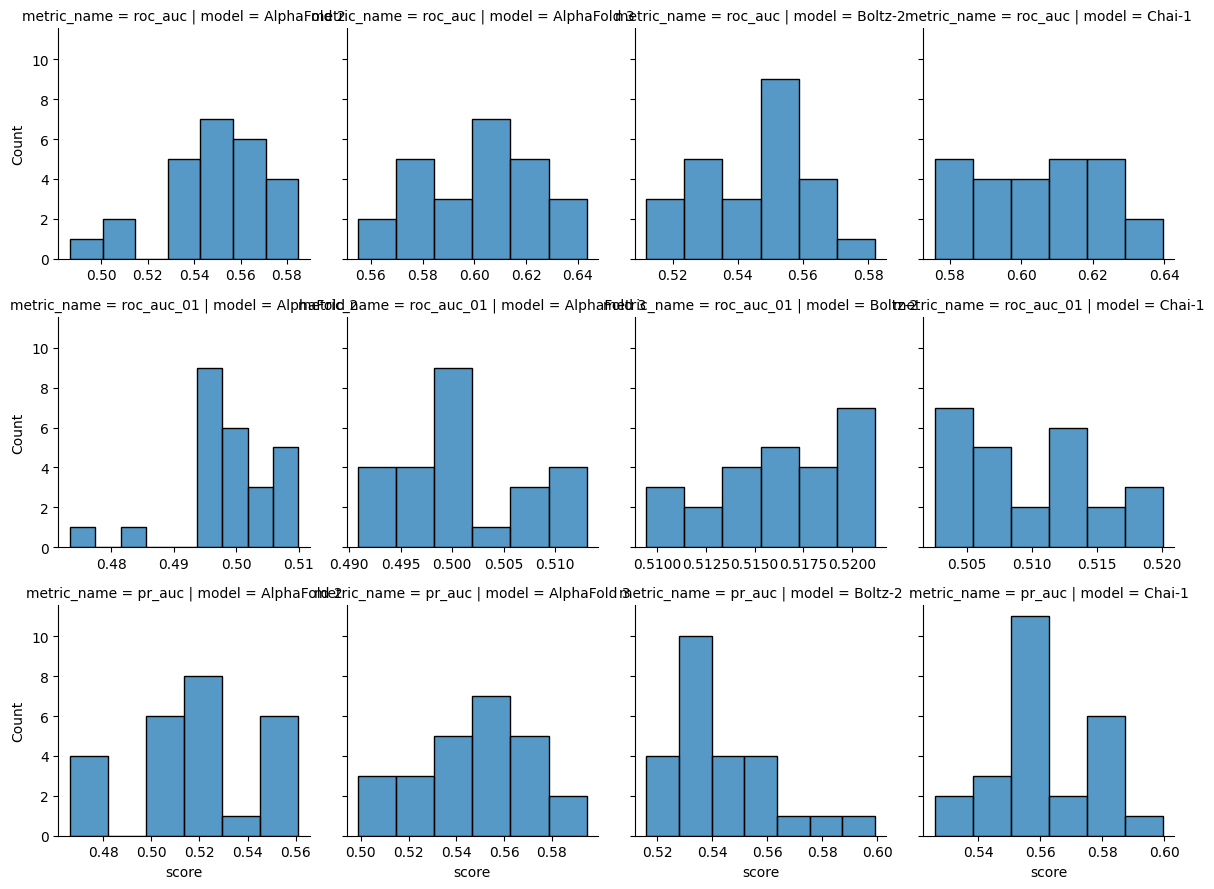

In [20]:
sns.FacetGrid(
    samples_metric_scores.melt(
        id_vars=['model', 'sample_num'],
        value_vars=['roc_auc', 'roc_auc_01', 'pr_auc'],
        var_name='metric_name',
        value_name='score',
    ),
    col='model',
    row='metric_name',
    sharex=False,
).map(sns.histplot, 'score')

sns.FacetGrid(
    samples_metric_scores_top_rank.melt(
        id_vars=['model', 'sample_num'],
        value_vars=['roc_auc', 'roc_auc_01', 'pr_auc'],
        var_name='metric_name',
        value_name='score',
    ),
    col='model',
    row='metric_name',
    sharex=False,
).map(sns.histplot, 'score')

plt.show()

In [21]:
def statistics_normal(data: pd.DataFrame, metric_name: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    overall = pg.anova(data, dv=metric_name, between='model')

    groups = list(data.groupby('model')[metric_name])

    significance_level = 0.05 / len(groups)

    post_hoc = collections.defaultdict(list)
    for (group1_name, group1), (group2_name, group2) in itertools.combinations(groups, 2):
        stat, p_val = stats.ttest_ind(group1, group2, alternative='two-sided')

        post_hoc['group1'].append(group1_name)
        post_hoc['group2'].append(group2_name)
        post_hoc['stat'].append(stat)
        post_hoc['p_val'].append(p_val)
        post_hoc['signficant'].append(p_val < significance_level)

    return overall, pd.DataFrame(post_hoc)

In [22]:
for metric_name in ('roc_auc', 'roc_auc_01', 'pr_auc'):
    print(format_metric_name(metric_name))

    for title, data in zip(('All', 'Top Ranked'), (samples_metric_scores, samples_metric_scores_top_rank), strict=True):
        print(title)
        overall, post_hoc = statistics_normal(data, metric_name)

        ipy_display.display(overall)
        ipy_display.display(post_hoc)
        print()

ROC-AUC
All


,Source,ddof1,ddof2,F,p-unc,np2
0,model,3,96,51.230866,7.368149e-20,0.615527


,group1,group2,stat,p_val,signficant
0,AlphaFold 2,AlphaFold 3,-7.850718,3.704384e-10,True
1,AlphaFold 2,Boltz-2,-0.534188,5.956769e-01,False
2,AlphaFold 2,Chai-1,-10.258394,1.091441e-13,True
3,AlphaFold 3,Boltz-2,7.550341,1.059618e-09,True
4,AlphaFold 3,Chai-1,-0.578870,5.653834e-01,False
5,Boltz-2,Chai-1,-9.978345,2.719076e-13,True



Top Ranked


,Source,ddof1,ddof2,F,p-unc,np2
0,model,3,96,61.011712,3.669285e-22,0.655957


...

,Source,ddof1,ddof2,F,p-unc,np2
0,model,3,96,7.184585,0.000211,0.183352


,group1,group2,stat,p_val,signficant
0,AlphaFold 2,AlphaFold 3,-2.190229,0.033398,False
1,AlphaFold 2,Boltz-2,-1.912543,0.061784,False
2,AlphaFold 2,Chai-1,-4.999415,0.000008,True
3,AlphaFold 3,Boltz-2,0.573698,0.568851,False
4,AlphaFold 3,Chai-1,-2.064283,0.044418,False
5,Boltz-2,Chai-1,-3.193491,0.002483,True



Top Ranked


,Source,ddof1,ddof2,F,p-unc,np2
0,model,3,96,14.96277,4.573872e-08,0.318609


,group1,group2,stat,p_val,signficant
0,AlphaFold 2,AlphaFold 3,-3.760805,4.602434e-04,True
1,AlphaFold 2,Boltz-2,-3.612714,7.235546e-04,True
2,AlphaFold 2,Chai-1,-6.561447,3.461497e-08,True
3,AlphaFold 3,Boltz-2,0.625005,5.349280e-01,False
4,AlphaFold 3,Chai-1,-2.300582,2.580357e-02,False
5,Boltz-2,Chai-1,-3.516974,9.650614e-04,True


### By Fold

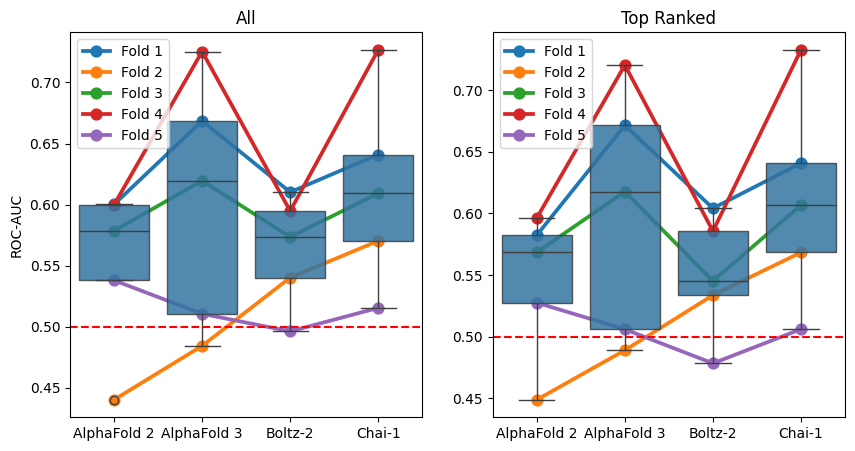

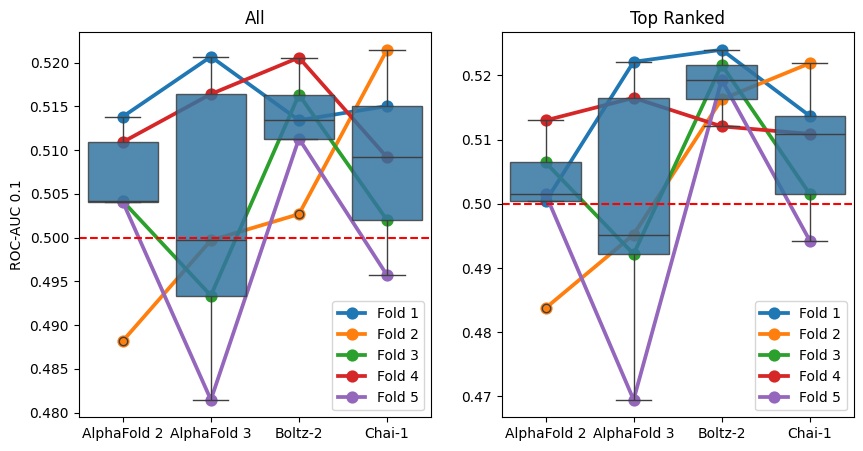

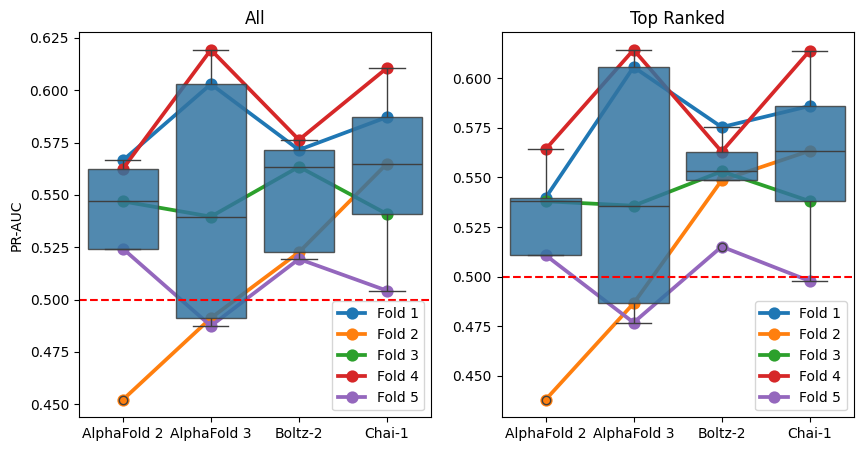

In [23]:
roc_aucs_by_fold = (
    confidence_scores.groupby(['model', 'fold'])
    .apply(lambda group: calculate_performance(group['cdr_pmhc_pae_score'], group['label']), include_groups=False)
    .reset_index()
)

roc_aucs_by_fold_top_rank = (
    confidence_scores.query('top_rank')
    .groupby(['model', 'fold'])
    .apply(lambda group: calculate_performance(group['cdr_pmhc_pae_score'], group['label']), include_groups=False)
    .reset_index()
)


for metric_name in ('roc_auc', 'roc_auc_01', 'pr_auc'):
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    for i, (ax, title, data) in enumerate(
        zip(axes, ('All', 'Top Ranked'), (roc_aucs_by_fold, roc_aucs_by_fold_top_rank), strict=True)
    ):
        sns.pointplot(data, x='model', y=metric_name, hue='fold', ax=ax)
        sns.boxplot(data, x='model', y=metric_name, boxprops={'alpha': 0.85}, ax=ax)

        ax.axhline(0.5, color='r', linestyle='dashed')

        ax.set_title(title)
        ax.set_xlabel('')

        handles, labels = ax.get_legend_handles_labels()
        new_labels = [f'Fold {label}' for label in labels]
        ax.legend(handles, new_labels)

        if i == 0:
            ax.set_ylabel(format_metric_name(metric_name))

        else:
            ax.set_ylabel('')

    plt.show()

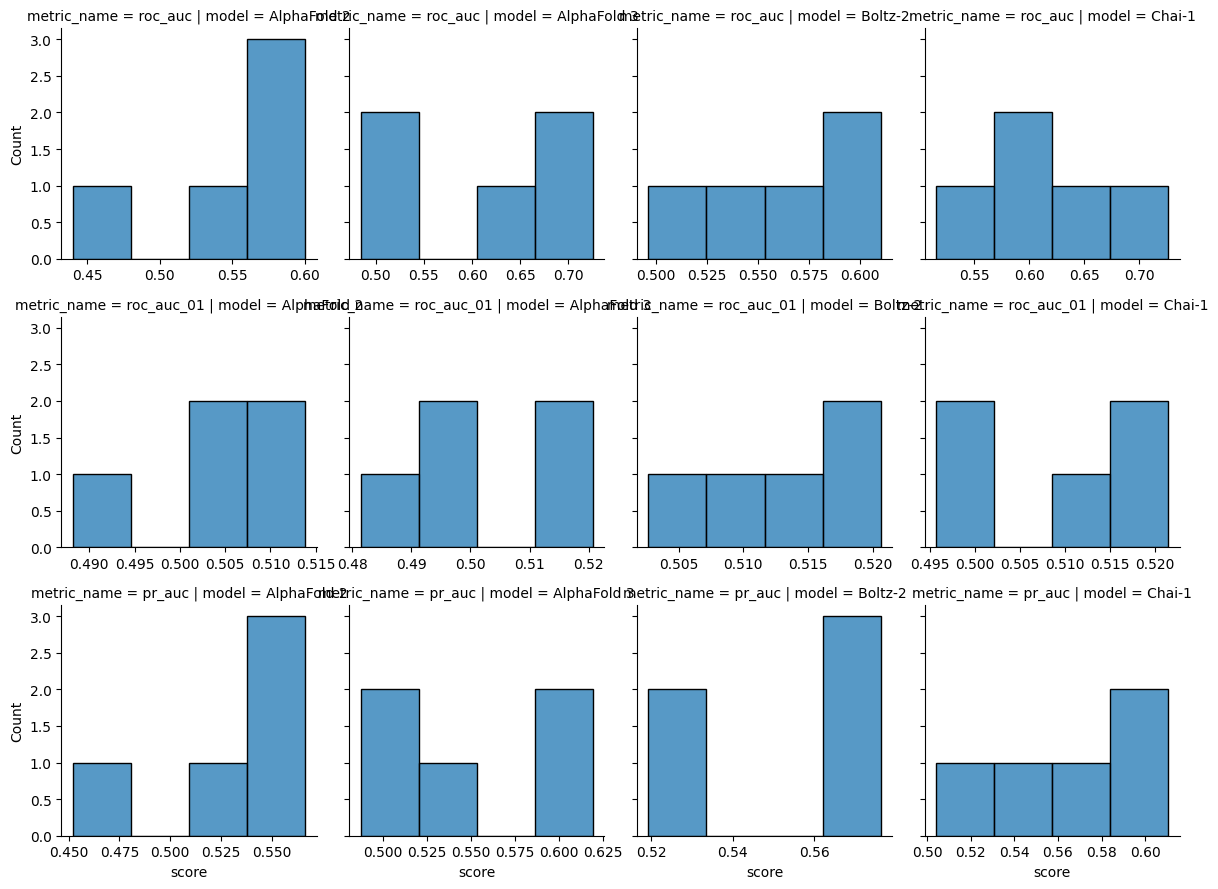

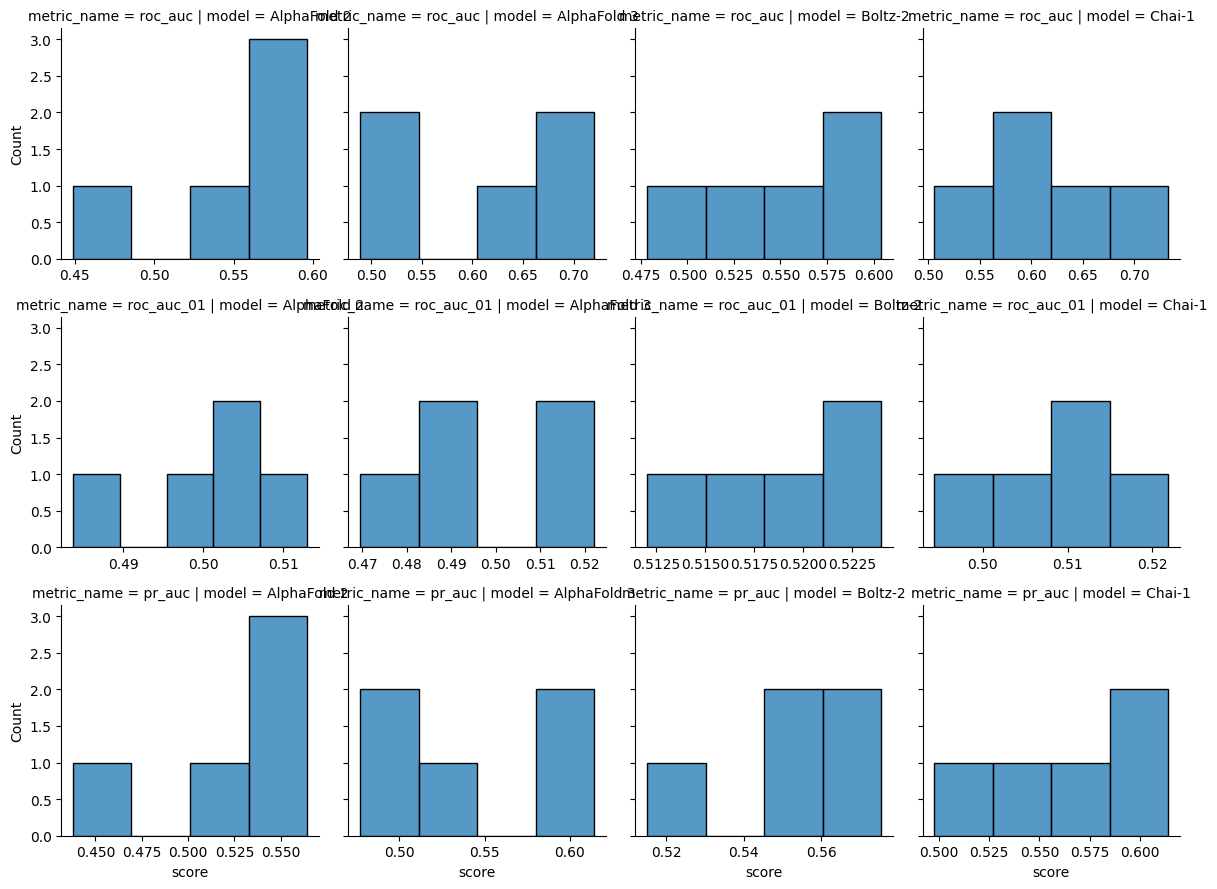

In [24]:
sns.FacetGrid(
    roc_aucs_by_fold.melt(
        id_vars=['model', 'fold'],
        value_vars=['roc_auc', 'roc_auc_01', 'pr_auc'],
        var_name='metric_name',
        value_name='score',
    ),
    col='model',
    row='metric_name',
    sharex=False,
).map(sns.histplot, 'score')

sns.FacetGrid(
    roc_aucs_by_fold_top_rank.melt(
        id_vars=['model', 'fold'],
        value_vars=['roc_auc', 'roc_auc_01', 'pr_auc'],
        var_name='metric_name',
        value_name='score',
    ),
    col='model',
    row='metric_name',
    sharex=False,
).map(sns.histplot, 'score')

plt.show()

In [25]:
def statistics_non_parametric(data: pd.DataFrame, metric_name: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    overall = pg.friedman(data, dv=metric_name, within='model', subject='fold', method='f')

    groups = list(data.set_index('fold').groupby('model')[metric_name])
    groups = [(group_name, group.sort_index()) for group_name, group in groups]

    significance_level = 0.05 / len(groups)

    post_hoc = collections.defaultdict(list)
    for (group1_name, group1), (group2_name, group2) in itertools.combinations(groups, 2):
        stat, p_val = stats.wilcoxon(group1, group2, alternative='greater')

        post_hoc['group1'].append(group1_name)
        post_hoc['group2'].append(group2_name)
        post_hoc['stat'].append(stat)
        post_hoc['p_val'].append(p_val)
        post_hoc['signficant'].append(p_val < significance_level)

    return overall, pd.DataFrame(post_hoc)

In [26]:
for metric_name in ('roc_auc', 'roc_auc_01', 'pr_auc'):
    print(format_metric_name(metric_name))

    for title, data in zip(('All', 'Top Ranked'), (roc_aucs_by_fold, roc_aucs_by_fold_top_rank), strict=True):
        print(title)
        overall, post_hoc = statistics_non_parametric(data, metric_name)

        ipy_display.display(overall)
        ipy_display.display(post_hoc)

        print()

    print()

ROC-AUC
All


,Source,W,ddof1,ddof2,F,p-unc
Friedman,model,0.424,2.6,10.4,2.944444,0.088004


,group1,group2,stat,p_val,signficant
0,AlphaFold 2,AlphaFold 3,1.0,0.96875,False
1,AlphaFold 2,Boltz-2,7.0,0.59375,False
2,AlphaFold 2,Chai-1,1.0,0.96875,False
3,AlphaFold 3,Boltz-2,12.0,0.15625,False
4,AlphaFold 3,Chai-1,7.0,0.59375,False
5,Boltz-2,Chai-1,0.0,1.00000,False



Top Ranked


,Source,W,ddof1,ddof2,F,p-unc
Friedman,model,0.424,2.6,10.4,2.944444,0.088004


...

,Source,W,ddof1,ddof2,F,p-unc
Friedman,model,0.088,2.6,10.4,0.385965,0.739405


,group1,group2,stat,p_val,signficant
0,AlphaFold 2,AlphaFold 3,4.0,0.84375,False
1,AlphaFold 2,Boltz-2,1.0,0.96875,False
2,AlphaFold 2,Chai-1,3.0,0.90625,False
3,AlphaFold 3,Boltz-2,7.0,0.59375,False
4,AlphaFold 3,Chai-1,5.0,0.78125,False
5,Boltz-2,Chai-1,4.0,0.84375,False



Top Ranked


,Source,W,ddof1,ddof2,F,p-unc
Friedman,model,0.168,2.6,10.4,0.807692,0.501417


,group1,group2,stat,p_val,signficant
0,AlphaFold 2,AlphaFold 3,3.0,0.90625,False
1,AlphaFold 2,Boltz-2,1.0,0.96875,False
2,AlphaFold 2,Chai-1,2.0,0.93750,False
3,AlphaFold 3,Boltz-2,6.0,0.68750,False
4,AlphaFold 3,Chai-1,4.0,0.84375,False
5,Boltz-2,Chai-1,7.0,0.59375,False


## Structure Quality

In [27]:
af3_confidence_scores_benchmark = pd.read_csv(
    '../data/interim/confidence_scores_af3_af3_tcrmodel2_3_recycles_benchmark.csv'
)

af3_confidence_scores_benchmark['top_rank'] = False
af3_confidence_scores_benchmark.loc[
    af3_confidence_scores_benchmark.groupby('name')['ranking_score'].idxmax(), 'top_rank'
] = True

af3_dockq_scores = pd.read_csv('../data/processed/predicted_af3_af3_tcrmodel2_3_recycles_dockq_benchmark.csv')
af3_dockq_scores['model'] = 'AlphaFold3'

af3_dockq_scores['pdb_id'] = af3_dockq_scores['name'].map(lambda name: name.split('_')[-2])

af3_dockq_scores = af3_dockq_scores.merge(af3_confidence_scores_benchmark, how='inner', on=['name', 'seed', 'sample'])

In [28]:
boltz_confidence_scores_benchmark = pd.read_csv('../data/interim/confidence_scores_boltz_af3_tcrmodel2_benchmark.csv')

boltz_confidence_scores_benchmark['top_rank'] = False
boltz_confidence_scores_benchmark.loc[
    boltz_confidence_scores_benchmark.groupby('name')['confidence_score'].idxmax(), 'top_rank'
] = True

boltz_dockq_scores = pd.read_csv('../data/processed/predicted_boltz_af3_tcrmodel2_dockq_benchmark.csv')
boltz_dockq_scores['model'] = 'Boltz-2'
boltz_dockq_scores['pdb_id'] = boltz_dockq_scores['name'].map(lambda name: name.split('_')[-2])

boltz_dockq_scores = boltz_dockq_scores.merge(
    boltz_confidence_scores_benchmark, how='inner', on=['name', 'seed', 'sample']
)

In [29]:
BOLTZ2_TRAINING_CUTOFF = '2023-06-01'

stcrdab_summary = pd.read_csv('../data/raw/stcrdab/db_summary.dat', sep='\t')

stcrdab_summary['date'] = pd.to_datetime(stcrdab_summary['date'], format=r'%m/%d/%y')
stcrdab_summary['chains'] = (
    stcrdab_summary[['Achain', 'Bchain', 'antigen_chain', 'mhc_chain1', 'mhc_chain2']].fillna('').apply(''.join, axis=1)
)

boltz_dockq_scores[['pdb', 'chains']] = boltz_dockq_scores['name'].str.split('_').apply(pd.Series)
boltz_dockq_scores_with_dates = boltz_dockq_scores.merge(stcrdab_summary, how='left', on=['pdb', 'chains'])

boltz_dockq_scores = boltz_dockq_scores[boltz_dockq_scores_with_dates['date'] > BOLTZ2_TRAINING_CUTOFF]

In [30]:
boltz_dockq_scores['pdb_id'].unique()

array(['8shi', '8i5c', '8i5d'], dtype=object)

In [31]:
chai_confidence_scores_benchmark = pd.read_csv('../data/interim/confidence_scores_chai_af3_tcrmodel2_benchmark.csv')

chai_confidence_scores_benchmark['top_rank'] = False
chai_confidence_scores_benchmark.loc[
    chai_confidence_scores_benchmark.groupby('name')['aggregate_score'].idxmax(), 'top_rank'
] = True

chai_dockq_scores = pd.read_csv('../data/processed/predicted_chai_af3_tcrmodel2_dockq_benchmark.csv')
chai_dockq_scores['model'] = 'Chai-1'
chai_dockq_scores['pdb_id'] = chai_dockq_scores['name'].map(lambda name: name.split('_')[-2])

chai_dockq_scores = chai_dockq_scores.merge(
    chai_confidence_scores_benchmark, how='inner', on=['name', 'seed', 'sample']
)

In [32]:
af2_confidence_scores_benchmark = pd.read_csv('../data/interim/confidence_scores_af2_af3_tcrmodel2_benchmark.csv')

af2_confidence_scores_benchmark['top_rank'] = False
af2_confidence_scores_benchmark.loc[
    af2_confidence_scores_benchmark.groupby('name')['ranking_confidence'].idxmax(), 'top_rank'
] = True

af2_dockq_scores = pd.read_csv('../data/processed/predicted_af2_af3_tcrmodel2_dockq_benchmark.csv')
af2_dockq_scores['model'] = 'AlphaFold2'
af2_dockq_scores['pdb_id'] = af2_dockq_scores['name'].map(lambda name: name.split('_')[-2])

af2_dockq_scores = af2_dockq_scores.merge(af2_confidence_scores_benchmark, how='inner', on=['name', 'seed', 'sample'])

In [33]:
dockq_scores = pd.concat([af3_dockq_scores, boltz_dockq_scores, chai_dockq_scores, af2_dockq_scores])

In [34]:
dockq_scores.loc[dockq_scores['DockQ'].isna(), 'DockQ'] = 0.0

In [35]:
CAPRI_ACCEPTABLE_CUTOFF = 0.23
CAPRI_MEDIUM_CUTOFF = 0.49
CAPRI_HIGH_CUTOFF = 0.80


def get_capri_classification(dockq: float) -> str:
    if dockq < CAPRI_ACCEPTABLE_CUTOFF:
        return 'Incorrect'

    if CAPRI_ACCEPTABLE_CUTOFF <= dockq < CAPRI_MEDIUM_CUTOFF:
        return 'Acceptable'

    if CAPRI_MEDIUM_CUTOFF <= dockq < CAPRI_HIGH_CUTOFF:
        return 'Medium'

    return 'High'

In [36]:
dockq_scores['capri_classification'] = dockq_scores['DockQ'].map(get_capri_classification)

In [37]:
dockq_scores_no_boltz = dockq_scores.query("model != 'Boltz-2'")

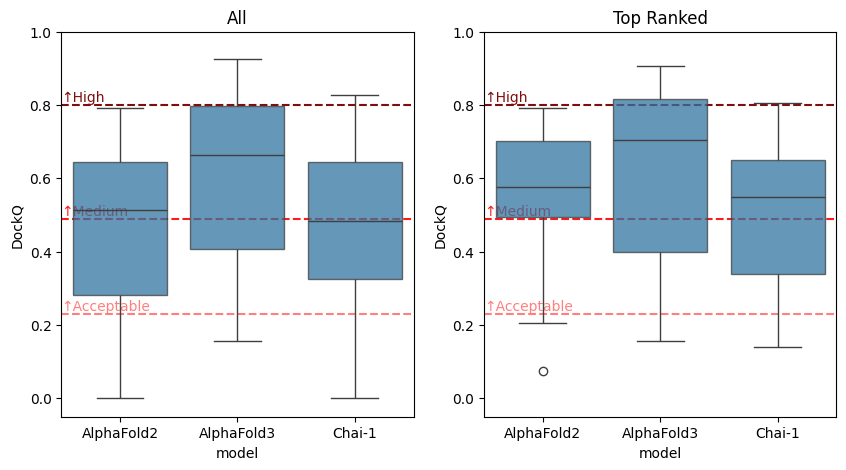

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, title, data in zip(
    axes, ('All', 'Top Ranked'), (dockq_scores_no_boltz, dockq_scores_no_boltz.query('top_rank')), strict=True
):
    ax.set_title(title)
    for label, cutoff, colour in (
        ('↑Acceptable', CAPRI_ACCEPTABLE_CUTOFF, '#ff7f7f'),
        ('↑Medium', CAPRI_MEDIUM_CUTOFF, '#ff1a1a'),
        ('↑High', CAPRI_HIGH_CUTOFF, '#7f0d0d'),
    ):
        ax.text(-0.5, cutoff + 0.01, label, color=colour)
        ax.axhline(cutoff, linestyle='dashed', color=colour)

    sns.boxplot(data.sort_values('model'), x='model', y='DockQ', ax=ax, zorder=3, boxprops={'alpha': 0.75})

    ax.set_ylim(-0.05, 1.0)

plt.show()

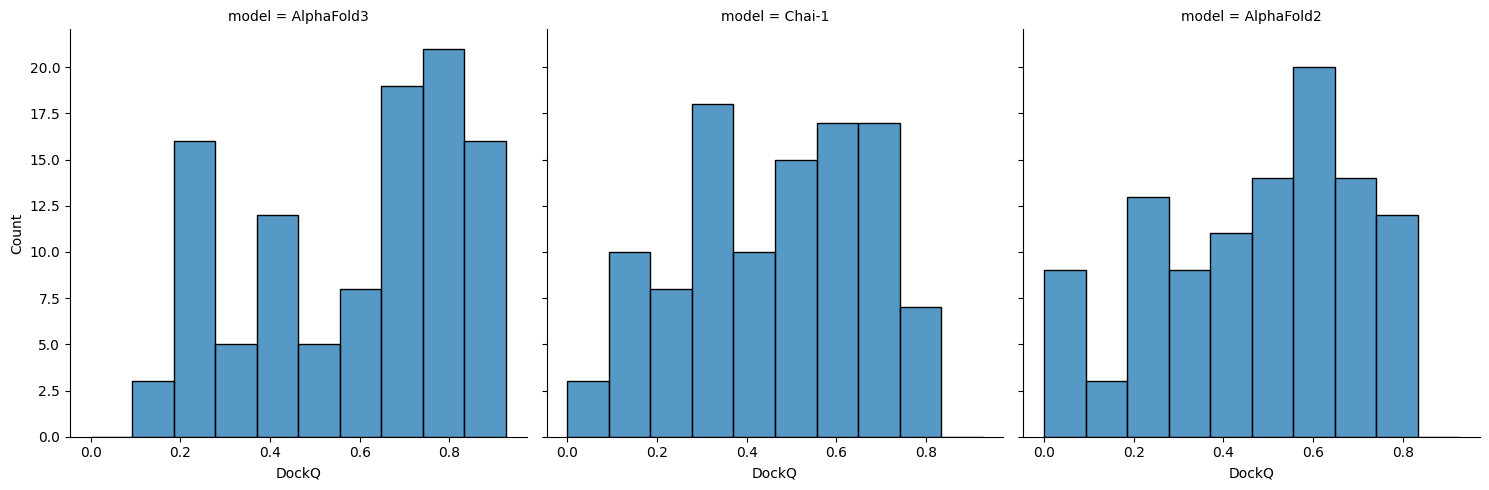

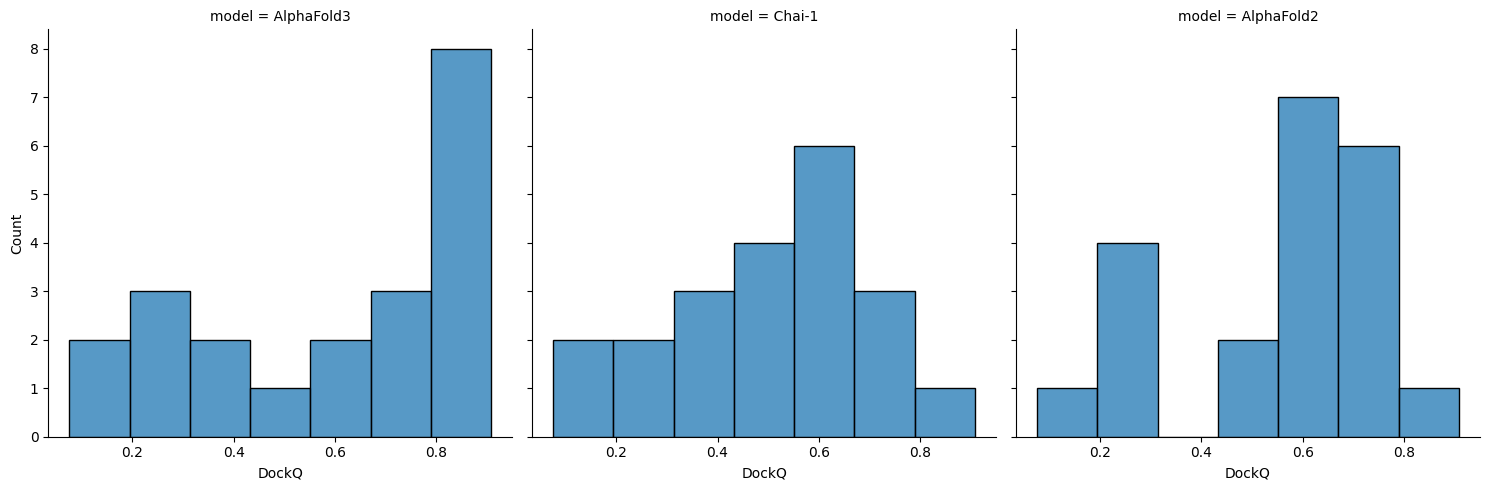

In [39]:
sns.displot(dockq_scores_no_boltz, col='model', x='DockQ', kind='hist')
sns.displot(dockq_scores_no_boltz.query('top_rank'), col='model', x='DockQ', kind='hist')

In [40]:
for title, data in zip(
    ('All', 'Top Ranked'), (dockq_scores_no_boltz, dockq_scores_no_boltz.query('top_rank')), strict=True
):
    print(title)

    ipy_display.display(pg.kruskal(data, dv='DockQ', between='model'))

    groups = list(data.groupby('model')['DockQ'])

    significance_level = 0.05 / len(groups)

    results = collections.defaultdict(list)
    for (group1_name, group1), (group2_name, group2) in itertools.combinations(groups, 2):
        stat, p_val = stats.ranksums(group1, group2, alternative='two-sided')

        results['group1'].append(group1_name)
        results['group2'].append(group2_name)
        results['stat'].append(stat)
        results['p_val'].append(p_val)
        results['signficant'].append(p_val < significance_level)

    ipy_display.display(pd.DataFrame(results))
    print()

All


,Source,ddof1,H,p-unc
Kruskal,model,2,21.381911,0.000023


,group1,group2,stat,p_val,signficant
0,AlphaFold2,AlphaFold3,-3.821336,0.000133,True
1,AlphaFold2,Chai-1,0.281632,0.778226,False
2,AlphaFold3,Chai-1,4.164290,0.000031,True



Top Ranked


,Source,ddof1,H,p-unc
Kruskal,model,2,2.473073,0.290388


,group1,group2,stat,p_val,signficant
0,AlphaFold2,AlphaFold3,-1.094275,0.273835,False
1,AlphaFold2,Chai-1,0.716939,0.473412,False
2,AlphaFold3,Chai-1,1.421299,0.155230,False


In [41]:
def plot_capri_classification(dockq_scores: pd.DataFrame, ax: Axes | None = None) -> Axes:
    capri_classification = dockq_scores.groupby('model')['capri_classification'].value_counts(normalize=True) * 100
    capri_classification.name = 'percent'
    capri_classification = capri_classification.reset_index()
    capri_classification = capri_classification.pivot_table(
        index='model', columns='capri_classification', values='percent'
    )

    order = ['High', 'Medium', 'Acceptable', 'Incorrect']
    colours = {
        'High': '#7f0d0d',
        'Medium': '#ff1a1a',
        'Acceptable': '#ff7f7f',
        'Incorrect': '#e6e6e6',
    }

    plot_ax = capri_classification.reindex(columns=order, fill_value=0).plot(
        kind='bar',
        stacked=True,
        color=[colours[col_name] for col_name in order],
        width=0.8,
        edgecolor='none',
        legend=False,
        ax=ax,
    )

    plot_ax.set_ylim(0, 100)
    plot_ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    plot_ax.set_ylabel('Success rate', fontsize=12)
    plot_ax.set_yticks([0, 25, 50, 75, 100])
    plot_ax.set_xlabel('')

    return plot_ax

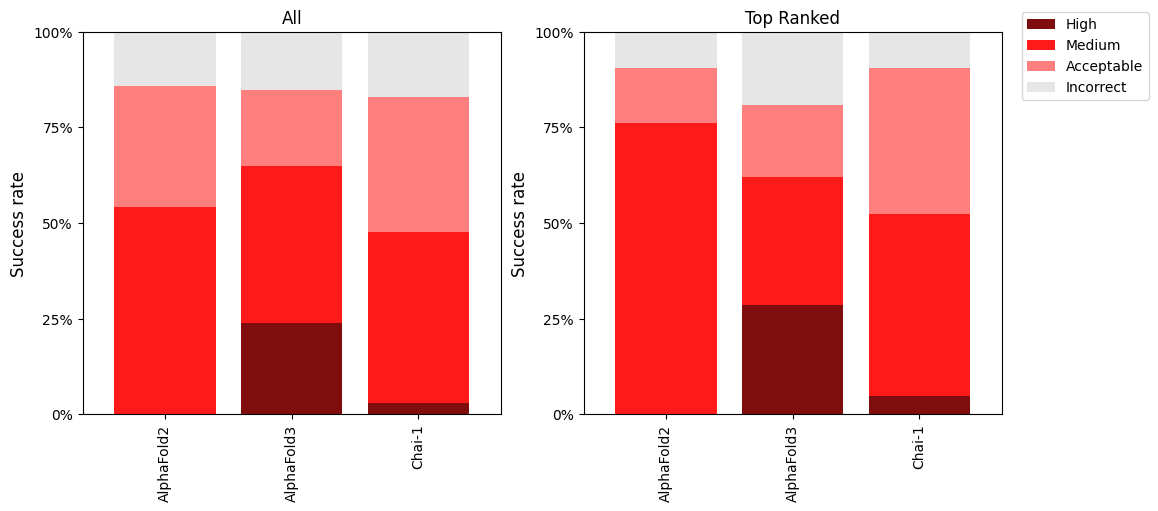

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5), constrained_layout=True)

for ax, title, data in zip(
    axes, ('All', 'Top Ranked'), (dockq_scores_no_boltz, dockq_scores_no_boltz.query('top_rank')), strict=True
):
    ax.set_title(title)
    plot_capri_classification(data, ax=ax)


handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, bbox_to_anchor=(1.15, 1))

plt.show()

In [43]:
dockq_scores_boltz_subset = dockq_scores[dockq_scores['pdb_id'].isin(['8shi', '8i5c', '8i5d'])]

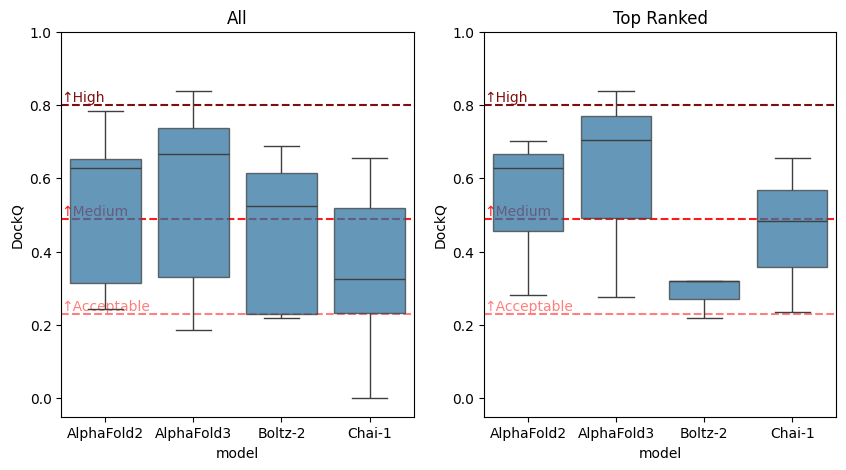

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, title, data in zip(
    axes, ('All', 'Top Ranked'), (dockq_scores_boltz_subset, dockq_scores_boltz_subset.query('top_rank')), strict=True
):
    ax.set_title(title)
    for label, cutoff, colour in (
        ('↑Acceptable', CAPRI_ACCEPTABLE_CUTOFF, '#ff7f7f'),
        ('↑Medium', CAPRI_MEDIUM_CUTOFF, '#ff1a1a'),
        ('↑High', CAPRI_HIGH_CUTOFF, '#7f0d0d'),
    ):
        ax.text(-0.5, cutoff + 0.01, label, color=colour)
        ax.axhline(cutoff, linestyle='dashed', color=colour)

    sns.boxplot(data.sort_values('model'), x='model', y='DockQ', ax=ax, zorder=3, boxprops={'alpha': 0.75})

    ax.set_ylim(-0.05, 1.0)

plt.show()

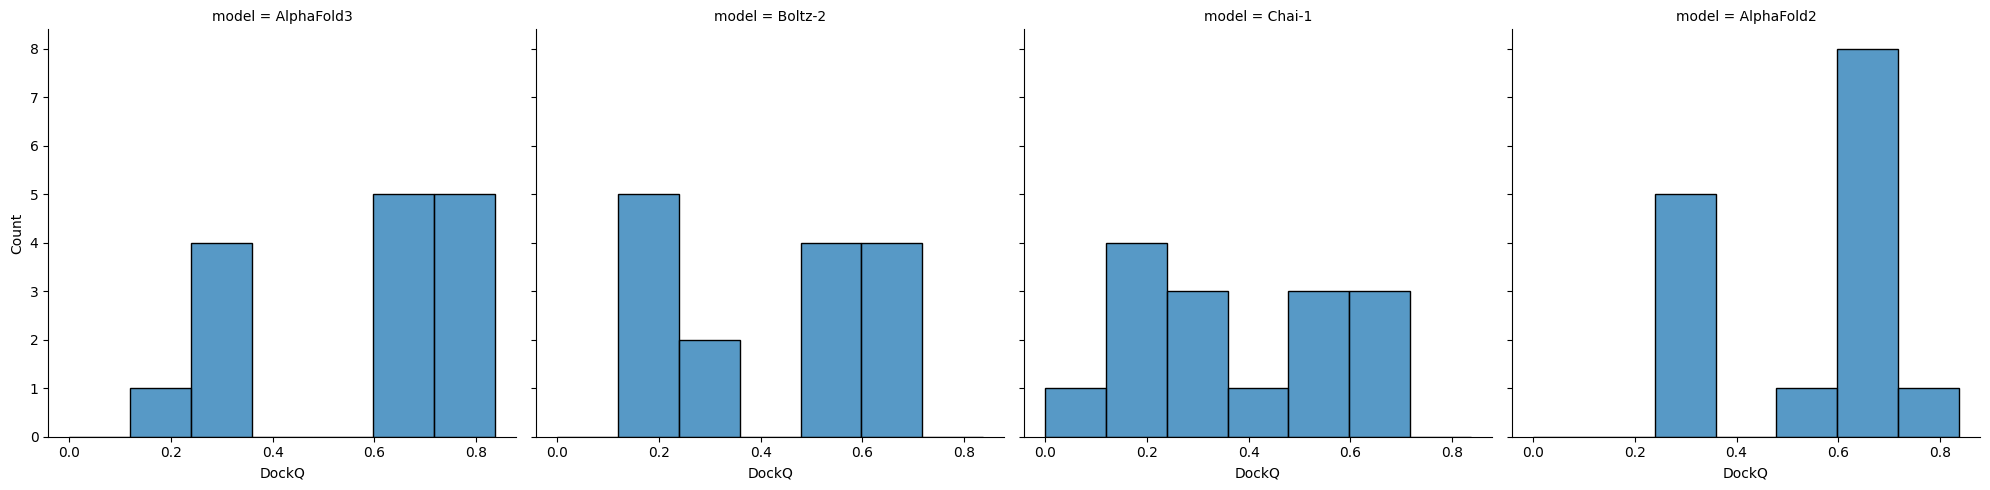

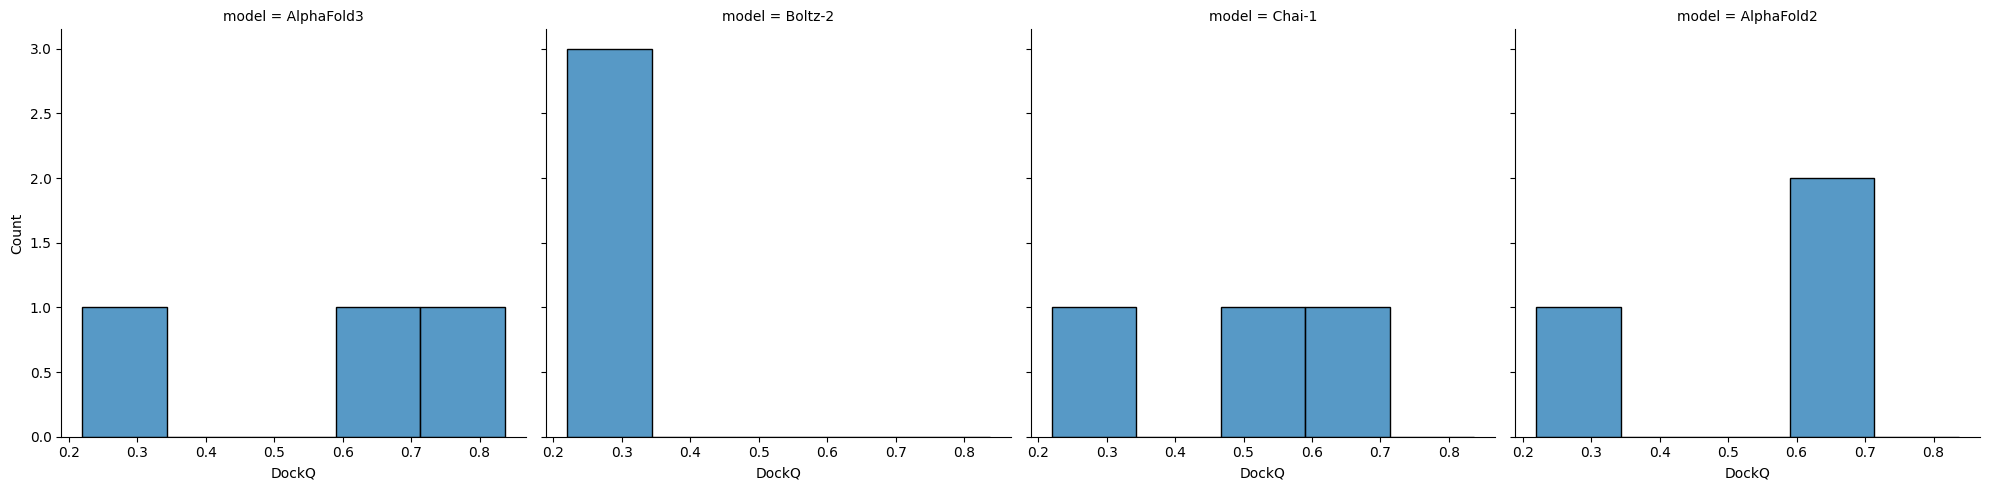

In [45]:
sns.displot(dockq_scores_boltz_subset, col='model', x='DockQ', kind='hist')
sns.displot(dockq_scores_boltz_subset.query('top_rank'), col='model', x='DockQ', kind='hist')

In [46]:
for title, data in zip(
    ('All', 'Top Ranked'), (dockq_scores_boltz_subset, dockq_scores_boltz_subset.query('top_rank')), strict=True
):
    print(title)

    ipy_display.display(pg.kruskal(data, dv='DockQ', between='model'))

    groups = list(data.groupby('model')['DockQ'])

    significance_level = 0.05 / len(groups)

    results = collections.defaultdict(list)
    for (group1_name, group1), (group2_name, group2) in itertools.combinations(groups, 2):
        stat, p_val = stats.ranksums(group1, group2, alternative='two-sided')

        results['group1'].append(group1_name)
        results['group2'].append(group2_name)
        results['stat'].append(stat)
        results['p_val'].append(p_val)
        results['signficant'].append(p_val < significance_level)

    ipy_display.display(pd.DataFrame(results))
    print()

All


,Source,ddof1,H,p-unc
Kruskal,model,3,12.020765,0.007312


,group1,group2,stat,p_val,signficant
0,AlphaFold2,AlphaFold3,-1.472471,0.140894,False
1,AlphaFold2,Boltz-2,1.804296,0.071185,False
2,AlphaFold2,Chai-1,2.343511,0.019103,False
3,AlphaFold3,Boltz-2,2.302033,0.021333,False
4,AlphaFold3,Chai-1,2.716813,0.006591,True
5,Boltz-2,Chai-1,0.808822,0.418617,False



Top Ranked


,Source,ddof1,H,p-unc
Kruskal,model,3,2.74359,0.43287


,group1,group2,stat,p_val,signficant
0,AlphaFold2,AlphaFold3,-0.654654,0.512691,False
1,AlphaFold2,Boltz-2,1.091089,0.275234,False
2,AlphaFold2,Chai-1,0.654654,0.512691,False
3,AlphaFold3,Boltz-2,1.091089,0.275234,False
4,AlphaFold3,Chai-1,1.091089,0.275234,False
5,Boltz-2,Chai-1,-1.091089,0.275234,False


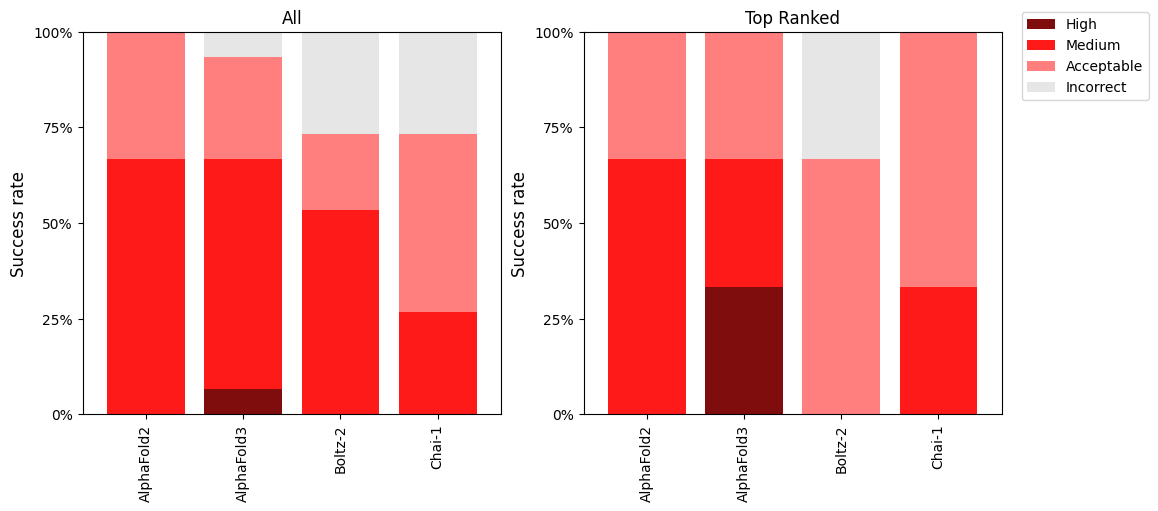

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5), constrained_layout=True)

for ax, title, data in zip(
    axes, ('All', 'Top Ranked'), (dockq_scores_boltz_subset, dockq_scores_boltz_subset.query('top_rank')), strict=True
):
    ax.set_title(title)
    plot_capri_classification(data, ax=ax)


handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, bbox_to_anchor=(1.15, 1))

plt.show()